# Titanic Survival Prediction – Data Cleaning Project

**Covers:** Assignment 1 (load + summary stats), Assignment 3 (mean/median imputation, LabelEncoder & OneHotEncoder) and Mini Project 1.

**Dataset:** Titanic (Kaggle). Download `train.csv` from https://www.kaggle.com/c/titanic/data and save it as `titanic.csv` in this folder.

## 1. Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

sns.set_style("whitegrid")

## 2. Load the dataset (Assignment 1)

In [5]:
import os

if os.path.exists("Titanic-Dataset.csv"):
    df = pd.read_csv("Titanic-Dataset.csv")
else:
    # Fallback: seaborn's built-in copy of the Titanic data (needs internet)
    df = sns.load_dataset("titanic").rename(columns={
        "survived": "Survived", "pclass": "Pclass", "sex": "Sex", "age": "Age",
        "sibsp": "SibSp", "parch": "Parch", "fare": "Fare", "embarked": "Embarked"})
    df["Cabin"] = df["deck"]
    df = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked"]]

print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Basic statistics: `.info()` and `.describe()`

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


## 4. Check missing data

In [9]:
missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": (df.isnull().mean() * 100).round(1)
})
missing[missing["Missing"] > 0].sort_values("Missing", ascending=False)

,Missing,Percent
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


## 5. Handle missing data

| Column | Strategy | Why |
|---|---|---|
| `Age` | **Median** | Age is right-skewed, so the median is more robust than the mean |
| `Embarked` | **Mode** (most frequent) | Categorical, so mean/median don't apply |
| `Fare` | **Median** (if any missing) | Fare is heavily skewed |
| `Cabin` | **Drop** | Most values are missing, so imputing would be guesswork |

First, a quick comparison of mean vs median for Age (Assignment 3):

In [10]:
print("Age mean  :", round(df["Age"].mean(), 2))
print("Age median:", df["Age"].median())
print("Skewness  :", round(df["Age"].skew(), 2))

Age mean  : 29.7
Age median: 28.0
Skewness  : 0.39


In [11]:
age_before = df["Age"].copy()   # keep the original for the before/after plot
df_clean = df.copy()

# Age: median imputation
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Embarked: mode imputation
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

# Fare: median imputation (only matters if some values are missing)
df_clean["Fare"] = df_clean["Fare"].fillna(df_clean["Fare"].median())

# Cabin: drop (too many missing values)
if "Cabin" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Cabin"])

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## 6. Encode categorical variables

### 6a. LabelEncoder (each category becomes an integer)

In [12]:
le_sex = LabelEncoder()
le_emb = LabelEncoder()

df_clean["Sex_Label"] = le_sex.fit_transform(df_clean["Sex"])
df_clean["Embarked_Label"] = le_emb.fit_transform(df_clean["Embarked"])

print("Sex mapping     :", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Embarked mapping:", dict(zip(le_emb.classes_, le_emb.transform(le_emb.classes_))))
df_clean[["Sex", "Sex_Label", "Embarked", "Embarked_Label"]].head()

Sex mapping     : {'female': np.int64(0), 'male': np.int64(1)}
Embarked mapping: {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}


,Sex,Sex_Label,Embarked,Embarked_Label
0,male,1,S,2
1,female,0,C,0
2,female,0,S,2
3,female,0,S,2
4,male,1,S,2


### 6b. OneHotEncoder (one 0/1 column per category)

LabelEncoder gives `Embarked` an artificial order (C < Q < S), which linear models can misread. One-hot encoding avoids that.

In [13]:
ohe = OneHotEncoder(sparse_output=False, dtype=int)

encoded = ohe.fit_transform(df_clean[["Sex", "Embarked"]])
ohe_cols = ohe.get_feature_names_out(["Sex", "Embarked"])
ohe_df = pd.DataFrame(encoded, columns=ohe_cols, index=df_clean.index)

df_clean = pd.concat([df_clean, ohe_df], axis=1)
df_clean[list(ohe_cols)].head()

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,1,0,0,1
1,1,0,1,0,0
2,1,0,0,0,1
3,1,0,0,0,1
4,0,1,0,0,1


## 7. Visualize the age distribution

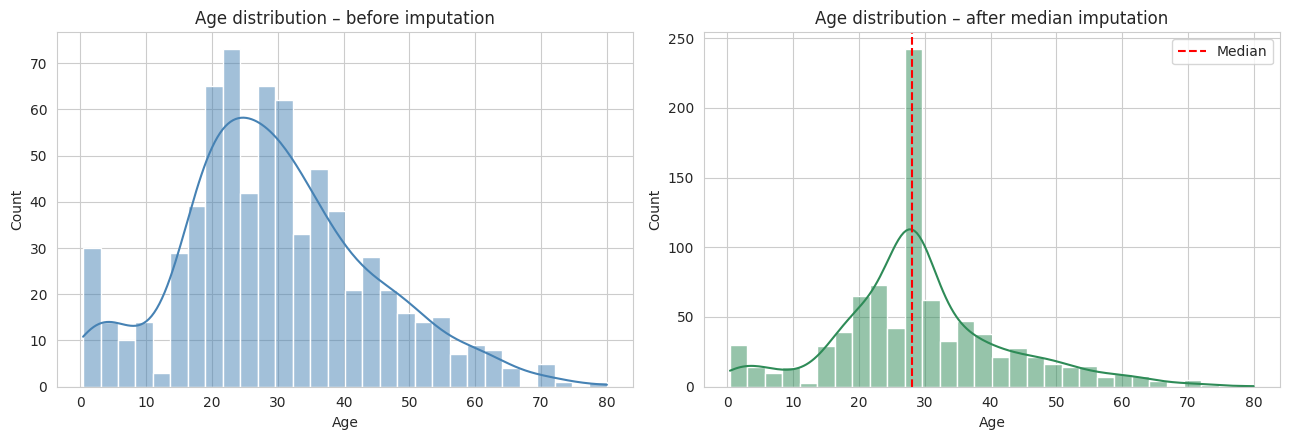

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Before imputation (missing values excluded)
sns.histplot(age_before.dropna(), bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Age distribution – before imputation")
axes[0].set_xlabel("Age")

# After median imputation
sns.histplot(df_clean["Age"], bins=30, kde=True, color="seagreen", ax=axes[1])
axes[1].axvline(df_clean["Age"].median(), color="red", linestyle="--", label="Median")
axes[1].set_title("Age distribution – after median imputation")
axes[1].set_xlabel("Age")
axes[1].legend()

plt.tight_layout()
plt.show()

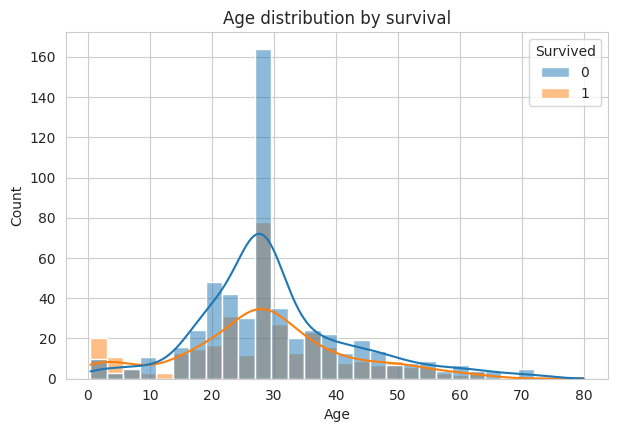

In [15]:
if "Survived" in df_clean.columns:
    plt.figure(figsize=(7, 4.5))
    sns.histplot(data=df_clean, x="Age", hue="Survived", bins=30, kde=True, multiple="layer")
    plt.title("Age distribution by survival")
    plt.show()

## 8. Final cleaned dataset and export

In [16]:
print("Shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
df_clean.head()

Shape: (891, 18)
Total missing values: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Sex_Label,Embarked_Label,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,1,2,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,0,0,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0,2,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,0,2,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1,2,0,1,0,0,1


In [17]:
df_clean.to_csv("titanic_cleaned.csv", index=False)
print("Saved: titanic_cleaned.csv")

Saved: titanic_cleaned.csv


## 9. Summary

- Loaded the Titanic data and summarised it with `.info()` and `.describe()`.
- Filled `Age` with the median and `Embarked` with the mode, and dropped `Cabin` (mostly missing).
- Encoded `Sex` and `Embarked` with both **LabelEncoder** and **OneHotEncoder**.
- Plotted the age distribution before and after imputation.
- Saved the cleaned data as `titanic_cleaned.csv`.